In [ ]:
import os
import random
from itertools import product
from pathlib import Path

# Keep this before importing torch when running the notebook on CPU only.
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score


## Model and training helpers
Core helpers for masked losses, LBFGS training, network metrics, cross-validation, and diagnostic plots.


In [ ]:
class LTIExact_Steady(nn.Module):
    def __init__(self, d, mask, A=None, X_star_init=None, scale=0.1, eye_shift=0.1, dtype=torch.float32):
        super().__init__()
        self.d = d
        self.register_buffer('mask', mask.to(dtype=torch.bool))

        device = self.mask.device
        I = torch.eye(d, dtype=dtype, device=device)
        if A is None:
            M = torch.randn(d, d, dtype=dtype, device=device)
            W0 = (M - M.T) * scale - eye_shift * I
        else:
            A_init = torch.as_tensor(A, dtype=dtype, device=device)
            W0 = A_init * scale - eye_shift * I

        self.W = nn.Parameter(W0 * self.mask)

        if X_star_init is None:
            X_star0 = torch.zeros(1, d, dtype=dtype, device=device)
        else:
            X_star0 = torch.as_tensor(X_star_init, dtype=dtype, device=device)

        self.X_star = nn.Parameter(X_star0)

    @property
    def A_eff(self):
        return self.W * self.mask

    def predict_traj(self, X0: torch.Tensor, t_span: torch.Tensor) -> torch.Tensor:
        A = self.A_eff
        device, dtype = A.device, A.dtype
        X_star = self.X_star

        X0 = X0.to(device=device, dtype=dtype)
        t_span = t_span.to(device=device, dtype=dtype)

        At = A.unsqueeze(0).unsqueeze(0) * t_span[..., None, None]
        E = torch.matrix_exp(At)

        X0_shift = X0 - X_star
        Y_centered = torch.einsum(
            'bid,btdk->btk',
            X0_shift[:, None, :],
            E.transpose(-1, -2),
        )
        Y_pred = Y_centered + X_star
        return Y_pred

    def forward(self, X0, t_span):
        return self.predict_traj(X0, t_span)


def make_pseudotime_bins(t_values, n_bins=8):
    t_values = np.asarray(t_values, dtype=float).reshape(-1)
    n_bins = max(2, min(int(n_bins), t_values.shape[0]))
    quantiles = np.linspace(0.0, 1.0, n_bins + 1)
    edges = np.quantile(t_values, quantiles)
    edges = np.unique(edges)
    if edges.shape[0] < 3:
        edges = np.array([t_values.min(), np.median(t_values), t_values.max()], dtype=float)
    bin_ids = np.digitize(t_values, edges[1:-1], right=False)
    bin_centers = np.array(
        [t_values[bin_ids == idx].mean() for idx in range(int(bin_ids.max()) + 1)],
        dtype=float,
    )
    return bin_ids, bin_centers


def stratified_pseudotime_train_val_split(
    t_values,
    train_fraction=0.8,
    n_bins=8,
    seed=0,
    force_train_indices=(0, -1),
):
    t_values = np.asarray(t_values, dtype=float).reshape(-1)
    n_obs = t_values.shape[0]
    rng = np.random.default_rng(seed)

    force_train_indices = np.asarray(force_train_indices, dtype=int).reshape(-1)
    force_train_indices = np.where(force_train_indices < 0, n_obs + force_train_indices, force_train_indices)
    force_train_indices = np.unique(force_train_indices)
    if np.any((force_train_indices < 0) | (force_train_indices >= n_obs)):
        raise ValueError('force_train_indices contains out-of-range entries.')

    bin_ids, bin_centers = make_pseudotime_bins(t_values, n_bins=n_bins)
    train_mask = np.zeros(n_obs, dtype=bool)
    val_mask = np.zeros(n_obs, dtype=bool)
    train_mask[force_train_indices] = True

    for bin_id in np.unique(bin_ids):
        bin_idx = np.flatnonzero(bin_ids == bin_id)
        candidates = np.array([idx for idx in bin_idx if idx not in force_train_indices], dtype=int)
        desired_val = int(round((1.0 - train_fraction) * len(bin_idx)))
        max_val = min(len(candidates), len(bin_idx) - 1)
        n_val = min(desired_val, max_val)
        if n_val > 0:
            chosen_val = rng.choice(candidates, size=n_val, replace=False)
        else:
            chosen_val = np.array([], dtype=int)
        val_mask[chosen_val] = True
        train_mask[np.setdiff1d(bin_idx, chosen_val, assume_unique=False)] = True

    train_mask[force_train_indices] = True
    val_mask[force_train_indices] = False

    if np.any(train_mask & val_mask):
        raise RuntimeError('Train/validation masks overlap.')
    if not train_mask.any() or not val_mask.any():
        raise RuntimeError('Train/validation split produced an empty partition.')

    split_df = pd.DataFrame({
        'obs_index': np.arange(n_obs, dtype=int),
        'pseudotime': t_values,
        'bin_id': bin_ids.astype(int),
        'is_forced_train': np.isin(np.arange(n_obs), force_train_indices),
        'split': np.where(train_mask, 'train', 'validation'),
    })
    split_df['bin_count'] = split_df.groupby('bin_id')['obs_index'].transform('size')

    return {
        'train_mask': train_mask,
        'val_mask': val_mask,
        'train_indices': np.flatnonzero(train_mask),
        'val_indices': np.flatnonzero(val_mask),
        'bin_ids': bin_ids.astype(int),
        'bin_centers': bin_centers,
        'forced_train_indices': force_train_indices,
        'split_df': split_df,
    }


def plot_pseudotime_split(split_df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    split_colors = {'train': '#1f77b4', 'validation': '#d62728'}
    for split_name, group in split_df.groupby('split', sort=False):
        axes[0].scatter(
            group['obs_index'],
            group['pseudotime'],
            s=28,
            alpha=0.85,
            color=split_colors[split_name],
            label=split_name,
        )
    axes[0].set_xlabel('Observation index (sorted pseudotime order)')
    axes[0].set_ylabel('Pseudotime')
    axes[0].set_title('Train/validation split across pseudotime')
    axes[0].legend()

    split_counts = (
        split_df.groupby(['bin_id', 'split'])['obs_index']
        .count()
        .unstack(fill_value=0)
        .reindex(columns=['train', 'validation'], fill_value=0)
    )
    split_counts.plot(kind='bar', stacked=True, ax=axes[1], color=[split_colors['train'], split_colors['validation']])
    axes[1].set_xlabel('Pseudotime bin')
    axes[1].set_ylabel('Number of observations')
    axes[1].set_title('Bin-wise split counts')
    axes[1].legend(title='Split')

    plt.tight_layout()
    plt.show()


def _masked_data_loss(Y_pred, Y_obs, mask, loss_type='mse', huber_delta=0.5):
    mask = torch.as_tensor(mask, dtype=torch.bool, device=Y_pred.device)
    if mask.ndim != 1:
        raise ValueError('mask must be one-dimensional over time/observations.')
    if int(mask.sum().item()) == 0:
        raise ValueError('mask selects zero observations.')

    Y_pred_sel = Y_pred[:, mask, :]
    Y_obs_sel = Y_obs[:, mask, :]

    if loss_type.lower() == 'mse':
        return F.mse_loss(Y_pred_sel, Y_obs_sel)
    if loss_type.lower() == 'huber':
        return F.huber_loss(Y_pred_sel, Y_obs_sel, delta=huber_delta, reduction='mean')
    raise ValueError("loss_type must be 'mse' or 'huber'.")


def _masked_regression_metrics(Y_pred, Y_obs, mask):
    mask = torch.as_tensor(mask, dtype=torch.bool, device=Y_pred.device)
    if mask.ndim != 1:
        raise ValueError('mask must be one-dimensional over time/observations.')
    if int(mask.sum().item()) == 0:
        raise ValueError('mask selects zero observations.')

    diff = Y_pred[:, mask, :] - Y_obs[:, mask, :]
    return {
        'mse': diff.pow(2).mean(),
        'mae': diff.abs().mean(),
    }


def _regularization_term(model, l1_lambda=0.0, l2_lambda=0.0):
    W_masked = model.W * model.mask
    reg = torch.zeros((), device=W_masked.device, dtype=W_masked.dtype)
    if l2_lambda > 0.0:
        reg = reg + l2_lambda * W_masked.pow(2).sum()
    if l1_lambda > 0.0:
        reg = reg + l1_lambda * W_masked.abs().sum()
    return reg


def _evaluate_model(
    model,
    X0,
    t_span,
    Y_obs,
    train_mask,
    val_mask,
    loss_type,
    huber_delta,
    l1_lambda,
    l2_lambda,
    *,
    compute_val=True,
):
    Y_pred = model(X0, t_span)
    train_data_loss = _masked_data_loss(Y_pred, Y_obs, train_mask, loss_type=loss_type, huber_delta=huber_delta)
    train_metrics = _masked_regression_metrics(Y_pred, Y_obs, train_mask)
    reg = _regularization_term(model, l1_lambda=l1_lambda, l2_lambda=l2_lambda)

    result = {
        'Y_pred': Y_pred,
        'train_data_loss': train_data_loss,
        'train_mse': train_metrics['mse'],
        'train_mae': train_metrics['mae'],
        'reg': reg,
        'train_total_loss': train_data_loss + reg,
    }

    if compute_val:
        val_data_loss = _masked_data_loss(Y_pred, Y_obs, val_mask, loss_type=loss_type, huber_delta=huber_delta)
        val_metrics = _masked_regression_metrics(Y_pred, Y_obs, val_mask)
        result['val_data_loss'] = val_data_loss
        result['val_mse'] = val_metrics['mse']
        result['val_mae'] = val_metrics['mae']
        result['val_total_loss'] = val_data_loss + reg
    else:
        result['val_data_loss'] = None
        result['val_mse'] = None
        result['val_mae'] = None
        result['val_total_loss'] = None

    return result


def edge_delta_val_loss_matrix(
    model,
    X0,
    t_span,
    Y_obs,
    val_mask,
    edge_mask,
    *,
    loss_type='huber',
    huber_delta=0.5,
):
    edge_mask = np.asarray(edge_mask, dtype=bool)
    d0, d1 = edge_mask.shape
    if d0 != model.d or d1 != model.d:
        raise ValueError(f'edge_mask shape {edge_mask.shape} does not match model dimension {(model.d, model.d)}.')

    device = next(model.parameters()).device
    X0 = X0.to(device)
    t_span = t_span.to(device)
    Y_obs = Y_obs.to(device)

    scores = np.zeros((model.d, model.d), dtype=float)
    with torch.no_grad():
        original_W = model.W.detach().clone()
        baseline_pred = model(X0, t_span)
        baseline_loss = float(_masked_data_loss(
            baseline_pred, Y_obs, val_mask, loss_type=loss_type, huber_delta=huber_delta
        ).detach().cpu().item())

        try:
            edge_indices = list(zip(*np.where(edge_mask)))
            for edge_num, (i, j) in enumerate(edge_indices, start=1):
                model.W.copy_(original_W)
                model.W[i, j] = 0.0
                perturbed_pred = model(X0, t_span)
                perturbed_loss = float(_masked_data_loss(
                    perturbed_pred, Y_obs, val_mask, loss_type=loss_type, huber_delta=huber_delta
                ).detach().cpu().item())
                scores[i, j] = perturbed_loss - baseline_loss
        finally:
            model.W.copy_(original_W)

    return scores, baseline_loss


def train_lti_lbfgs_with_validation(
    model,
    X0,
    t_span,
    Y_obs,
    train_mask,
    val_mask,
    A_true_list,
    Mask_auroc,
    *,
    loss_type='huber',
    huber_delta=2.5,
    l1_lambda=1e-4,
    l2_lambda=1e-7,
    lr=0.3,
    epochs=50,
    lbfgs_max_iter=20,
    lbfgs_history_size=10,
    lbfgs_line_search_fn='strong_wolfe',
    optimizer_tolerance_grad=1e-7,
    optimizer_tolerance_change=1e-9,
    stop_tolerance_change=1e-9,
    stop_on_loss=False,
    stop_on_parameter=False,
    patience_level=1,
    device=None,
):
    if device is None:
        device = next(model.parameters()).device

    X0 = X0.to(device)
    t_span = t_span.to(device)
    Y_obs = Y_obs.to(device)
    train_mask = np.asarray(train_mask, dtype=bool)
    val_mask = np.asarray(val_mask, dtype=bool)

    opt = torch.optim.LBFGS(
        model.parameters(),
        lr=lr,
        max_iter=lbfgs_max_iter,
        history_size=lbfgs_history_size,
        line_search_fn=lbfgs_line_search_fn,
        tolerance_grad=optimizer_tolerance_grad,
        tolerance_change=optimizer_tolerance_change,
    )

    history_rows = []
    best_state_dict = None
    best_val_data_loss = float('inf')
    best_epoch = None
    best_A = None
    stopped_early = False
    stop_epoch = None
    stop_reasons = []
    previous_train_loss = None
    patience_level = max(1, int(patience_level))
    patience_counters = {
        'loss': 0,
        'parameter_A': 0,
        'parameter_X_star': 0,
    }

    for epoch in range(epochs):
        with torch.no_grad():
            A_before = model.A_eff.detach().clone()
            X_star_before = model.X_star.detach().clone()
            epoch_state_dict = {k: v.detach().clone() for k, v in model.state_dict().items()}

        def closure():
            opt.zero_grad(set_to_none=True)
            train_eval = _evaluate_model(
                model, X0, t_span, Y_obs, train_mask, val_mask,
                loss_type, huber_delta, l1_lambda, l2_lambda,
                compute_val=False,
            )
            raw_loss = train_eval['train_total_loss']
            if torch.isfinite(raw_loss):
                loss = raw_loss
            else:
                zero_link = torch.zeros((), device=device, dtype=raw_loss.dtype)
                for param in model.parameters():
                    zero_link = zero_link + param.sum() * 0.0
                loss = torch.nan_to_num(raw_loss, nan=1e100, posinf=1e100, neginf=1e100) + zero_link
            loss.backward()
            return loss

        opt.step(closure)

        with torch.no_grad():
            post_eval = _evaluate_model(
                model, X0, t_span, Y_obs, train_mask, val_mask,
                loss_type, huber_delta, l1_lambda, l2_lambda,
            )
            A_after = model.A_eff.detach().clone()
            X_star_after = model.X_star.detach().clone()
            post_finite = bool(
                torch.isfinite(A_after).all().item()
                and torch.isfinite(X_star_after).all().item()
                and torch.isfinite(post_eval['train_total_loss']).item()
                and torch.isfinite(post_eval['val_total_loss']).item()
            )

            if not post_finite:
                model.load_state_dict(epoch_state_dict)
                opt.zero_grad(set_to_none=True)
                post_eval = _evaluate_model(
                    model, X0, t_span, Y_obs, train_mask, val_mask,
                    loss_type, huber_delta, l1_lambda, l2_lambda,
                )
                A_after = model.A_eff.detach().clone()
                X_star_after = model.X_star.detach().clone()

            A_eff_np = A_after.cpu().numpy()
            if not np.isfinite(A_eff_np).all():
                raise ValueError(f'Rollback failed: non-finite values remain in A_eff at epoch {epoch}.')

        train_loss = float(post_eval['train_data_loss'].item())
        val_loss = float(post_eval['val_data_loss'].item())
        loss_change_abs = np.inf if previous_train_loss is None else abs(train_loss - previous_train_loss)
        previous_train_loss = train_loss
        delta_A_max_abs = float((A_after - A_before).abs().max().item())
        delta_X_star_max_abs = float((X_star_after - X_star_before).abs().max().item())

        meets_loss_change = bool(loss_change_abs <= stop_tolerance_change) if np.isfinite(loss_change_abs) else False
        meets_parameter_A = bool(delta_A_max_abs <= stop_tolerance_change)
        meets_parameter_X_star = bool(delta_X_star_max_abs <= stop_tolerance_change)

        patience_counters['loss'] = patience_counters['loss'] + 1 if meets_loss_change else 0
        patience_counters['parameter_A'] = patience_counters['parameter_A'] + 1 if meets_parameter_A else 0
        patience_counters['parameter_X_star'] = patience_counters['parameter_X_star'] + 1 if meets_parameter_X_star else 0

        stop_reasons_epoch = []
        if stop_on_loss and patience_counters['loss'] >= patience_level:
            stop_reasons_epoch.append(
                f'training_loss_change <= stop_tolerance_change for {patience_level} consecutive epochs'
            )
        if (
            stop_on_parameter
            and patience_counters['parameter_A'] >= patience_level
            and patience_counters['parameter_X_star'] >= patience_level
        ):
            stop_reasons_epoch.append(
                f'parameter_change (delta_A_max_abs and delta_X_star_max_abs) <= stop_tolerance_change for {patience_level} consecutive epochs'
            )
        if not post_finite:
            stop_reasons_epoch.append('nonfinite_lbfgs_step_rolled_back')

        metric_row = {
            'epoch': int(epoch),
            'train_data_loss_post': train_loss,
            'val_data_loss_post': val_loss,
            'train_mse_post': float(post_eval['train_mse'].item()),
            'val_mse_post': float(post_eval['val_mse'].item()),
            'train_mae_post': float(post_eval['train_mae'].item()),
            'val_mae_post': float(post_eval['val_mae'].item()),
            'loss_change_abs': float(loss_change_abs),
            'delta_A_max_abs': delta_A_max_abs,
            'delta_X_star_max_abs': delta_X_star_max_abs,
            'stop_triggered': bool(stop_reasons_epoch),
            'stop_reason': '|'.join(stop_reasons_epoch),
        }

        for i, A_true in enumerate(A_true_list):
            metric_row[f'GS{i}_auroc_absA'] = float(auroc_from_matrices(np.abs(A_eff_np), A_true, mask=Mask_auroc))

        history_rows.append(metric_row)

        if metric_row['val_data_loss_post'] < best_val_data_loss:
            best_val_data_loss = metric_row['val_data_loss_post']
            best_epoch = int(epoch)
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_A = A_eff_np.copy()

        if metric_row['stop_triggered']:
            stopped_early = True
            stop_epoch = int(epoch)
            stop_reasons = stop_reasons_epoch.copy()
            break

    history_df = pd.DataFrame(history_rows)
    return {
        'best_val_data_loss': float(best_val_data_loss),
        'best_epoch': int(best_epoch) if best_epoch is not None else None,
        'best_state_dict': best_state_dict,
        'best_A': best_A,
        'history_df': history_df,
        'optimizer_tolerance_grad': float(optimizer_tolerance_grad),
        'optimizer_tolerance_change': float(optimizer_tolerance_change),
        'stop_tolerance_change': float(stop_tolerance_change),
        'stopped_early': bool(stopped_early),
        'stop_epoch': int(stop_epoch) if stop_epoch is not None else None,
        'stop_reason': '|'.join(stop_reasons),
    }


# 1. Ordered Smooth Data2 with SCODE TFTF gold standard


In [ ]:
DATA_DIR = Path("/N/slate/vinshar/ODE/ExactLinearODE/ODE_PERTURBATIONS/data_ode/data2")

GeneExp_Smooth = np.loadtxt(DATA_DIR / "datamatrix_ordered_smooth_10.txt")
Time = np.loadtxt(DATA_DIR / "pseudotime_ordered.txt")

A_new_true = (np.loadtxt(DATA_DIR / "A.txt") != 0).astype(int)
np.fill_diagonal(A_new_true, 0)


In [ ]:
perm = np.argsort(Time)
Time_sorted = Time[perm]
GeneExp_Smooth_sorted_T = GeneExp_Smooth[:, perm].T

t_span = torch.tensor(Time_sorted[None, :], dtype=torch.float32)
Y_obs_Smooth = torch.tensor(GeneExp_Smooth_sorted_T[None, :, :], dtype=torch.float32)
X0 = Y_obs_Smooth[0, 0, :][None, :]

B, T, d = Y_obs_Smooth.shape
Mask = torch.ones((d, d), dtype=torch.bool)


## Hyperparameter Tuning Setup
Smoothed Data2 expression is fit with the SCODE TFTF gold standard. The pipeline keeps the fixed alternating 80/20 validation split, 5-fold CV inside the training portion, median validation MAE selection with rank-stability tie-breaking, CSV outputs, diagnostic plots, final refit, and perturbation scoring.


In [ ]:


def stratified_pseudotime_kfold_split(
    t_values,
    n_splits=5,
    n_bins=8,
    seed=0,
    force_train_indices=(),
):
    t_values = np.asarray(t_values, dtype=float).reshape(-1)
    n_obs = t_values.shape[0]
    rng = np.random.default_rng(seed)

    force_train_indices = np.asarray(force_train_indices, dtype=int).reshape(-1)
    if force_train_indices.size:
        force_train_indices = np.where(force_train_indices < 0, n_obs + force_train_indices, force_train_indices)
        force_train_indices = np.unique(force_train_indices)
        if np.any((force_train_indices < 0) | (force_train_indices >= n_obs)):
            raise ValueError('force_train_indices contains out-of-range entries.')

    bin_ids, _ = make_pseudotime_bins(t_values, n_bins=n_bins)
    fold_ids = np.full(n_obs, -1, dtype=int)

    for bin_id in np.unique(bin_ids):
        bin_idx = np.flatnonzero(bin_ids == bin_id)
        candidates = np.array([idx for idx in bin_idx if idx not in force_train_indices], dtype=int)
        if candidates.size == 0:
            continue
        rng.shuffle(candidates)
        for local_i, obs_idx in enumerate(candidates):
            fold_ids[obs_idx] = int(local_i % n_splits)

    remaining = np.setdiff1d(np.arange(n_obs), force_train_indices)
    if np.any(fold_ids[remaining] < 0):
        raise RuntimeError('Some non-forced observations were not assigned to any fold.')

    fold_masks = []
    for fold_id in range(n_splits):
        heldout_mask = fold_ids == fold_id
        train_mask = ~heldout_mask
        train_mask[force_train_indices] = True
        heldout_mask[force_train_indices] = False
        if not heldout_mask.any():
            raise RuntimeError(f'Fold {fold_id} has no heldout observations.')
        fold_masks.append({
            'fold_id': fold_id + 1,
            'train_mask': train_mask.copy(),
            'heldout_mask': heldout_mask.copy(),
            'train_indices': np.flatnonzero(train_mask),
            'heldout_indices': np.flatnonzero(heldout_mask),
        })

    fold_df = pd.DataFrame({
        'local_index': np.arange(n_obs, dtype=int),
        'pseudotime': t_values,
        'bin_id': bin_ids.astype(int),
        'fold_id': np.where(fold_ids >= 0, fold_ids + 1, 0),
        'is_forced_train': np.isin(np.arange(n_obs), force_train_indices),
    })
    fold_df['fold_label'] = np.where(fold_df['is_forced_train'], 'always_train', 'fold_' + fold_df['fold_id'].astype(str))
    return {
        'fold_masks': fold_masks,
        'fold_df': fold_df,
        'forced_train_indices': force_train_indices,
    }


def extract_stop_row_from_history(history_df):
    stop_df = history_df[history_df['stop_triggered']]
    if not stop_df.empty:
        return stop_df.iloc[0].copy()
    return history_df.iloc[-1].copy()


def format_hparam(value):
    return f'{value:g}' if value != 0 else '0'


def maybe_set_log_scale(ax, values, axis='x', ratio_threshold=50.0):
    vals = np.asarray(values, dtype=float)
    vals = vals[np.isfinite(vals)]
    vals = vals[vals > 0]
    if vals.size < 2:
        return
    vmin = float(vals.min())
    vmax = float(vals.max())
    if vmin <= 0:
        return
    if vmax / vmin >= ratio_threshold:
        if axis == 'x':
            ax.set_xscale('log')
        else:
            ax.set_yscale('log')


def plot_loss_auroc_relationships(all_history_df, output_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sc = axes[0].scatter(
        all_history_df['train_loss'],
        all_history_df['val_loss'],
        c=all_history_df['auroc'],
        cmap='viridis',
        s=8,
        alpha=0.25,
        edgecolors='none',
    )
    axes[0].set_xlabel('Training loss')
    axes[0].set_ylabel('Validation loss')
    axes[0].set_title('Train vs validation loss')
    maybe_set_log_scale(axes[0], all_history_df['train_loss'], axis='x')
    maybe_set_log_scale(axes[0], all_history_df['val_loss'], axis='y')

    axes[1].scatter(all_history_df['train_loss'], all_history_df['auroc'], s=8, alpha=0.25, color='#1f77b4', edgecolors='none')
    axes[1].set_xlabel('Training loss')
    axes[1].set_ylabel('AUROC')
    axes[1].set_title('Training loss vs AUROC')
    maybe_set_log_scale(axes[1], all_history_df['train_loss'], axis='x')

    axes[2].scatter(all_history_df['val_loss'], all_history_df['auroc'], s=8, alpha=0.25, color='#2ca02c', edgecolors='none')
    axes[2].set_xlabel('Validation loss')
    axes[2].set_ylabel('AUROC')
    axes[2].set_title('Validation loss vs AUROC')
    maybe_set_log_scale(axes[2], all_history_df['val_loss'], axis='x')

    cbar = fig.colorbar(sc, ax=axes[0], fraction=0.046, pad=0.04)
    cbar.set_label('AUROC')
    plt.tight_layout()
    if output_path is not None:
        fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()


def _finite_pair_arrays(df, x_col, y_col):
    if x_col not in df.columns or y_col not in df.columns:
        return np.array([], dtype=float), np.array([], dtype=float)
    x = pd.to_numeric(df[x_col], errors='coerce').to_numpy(dtype=float)
    y = pd.to_numeric(df[y_col], errors='coerce').to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    return x[mask], y[mask]


def plot_loss_mse_relationships(all_history_df, output_path=None):
    specs = [
        ('train_loss', 'train_mse', 'Training loss', 'Training MSE'),
        ('val_loss', 'val_mse', 'Validation loss', 'Validation MSE'),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (x_col, y_col, xlabel, ylabel) in zip(axes, specs):
        x, y = _finite_pair_arrays(all_history_df, x_col, y_col)
        if x.size:
            ax.scatter(x, y, s=8, alpha=0.25, color='#1f77b4', edgecolors='none')
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(f'{xlabel} vs {ylabel}')
        ax.grid(alpha=0.2)
        maybe_set_log_scale(ax, x, axis='x')
        maybe_set_log_scale(ax, y, axis='y')

    fig.tight_layout()
    if output_path is not None:
        fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()


def plot_mse_auroc_relationships(all_history_df, output_path=None):
    specs = [
        ('train_mse', 'Training MSE'),
        ('val_mse', 'Validation MSE'),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (x_col, xlabel) in zip(axes, specs):
        x, y = _finite_pair_arrays(all_history_df, x_col, 'auroc')
        if x.size:
            ax.scatter(x, y, s=8, alpha=0.25, color='#2ca02c', edgecolors='none')
        ax.set_xlabel(xlabel)
        ax.set_ylabel('AUROC')
        ax.set_title(f'{xlabel} vs AUROC')
        ax.grid(alpha=0.2)
        maybe_set_log_scale(ax, x, axis='x')

    fig.tight_layout()
    if output_path is not None:
        fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()


## Fixed alternating 80/20 train-validation split


In [ ]:
SPLIT_CONFIG = {
    'train_fraction': 0.8,
    'val_fraction': 0.2,
    'split_mode': 'alternating_80_20',
    'preferred_val_offset': 1,
}

split_time_values = np.asarray(Time_sorted, dtype=float).reshape(-1)
if split_time_values.shape[0] != Y_obs_Smooth.shape[1]:
    raise ValueError(
        f'Split time axis length {split_time_values.shape[0]} does not match Y_obs_Smooth time length {Y_obs_Smooth.shape[1]}.'
    )

n_obs = split_time_values.shape[0]
val_fraction = float(SPLIT_CONFIG['val_fraction'])
val_count_target = int(round(val_fraction * n_obs))
val_count_target = max(1, min(n_obs - 2, val_count_target))
period = int(round(1.0 / val_fraction))
period = max(2, period)

preferred_offset = int(SPLIT_CONFIG['preferred_val_offset']) % period
candidate_offsets = [preferred_offset] + [offset for offset in range(period) if offset != preferred_offset]
best_val_indices = None
best_offset = None
best_score = None
for offset in candidate_offsets:
    candidate = np.arange(offset, n_obs, period, dtype=int)
    candidate = candidate[(candidate != 0) & (candidate != n_obs - 1)]
    score = (abs(candidate.size - val_count_target), int(candidate.size == 0))
    if best_score is None or score < best_score:
        best_score = score
        best_offset = offset
        best_val_indices = candidate

val_indices = np.asarray(best_val_indices, dtype=int)
if val_indices.size > val_count_target:
    keep_positions = np.linspace(0, val_indices.size - 1, val_count_target).round().astype(int)
    val_indices = np.unique(val_indices[keep_positions])
while val_indices.size < val_count_target:
    candidates = np.setdiff1d(np.arange(1, n_obs - 1, dtype=int), val_indices, assume_unique=False)
    if candidates.size == 0:
        break
    ideal_positions = (np.arange(val_count_target, dtype=float) + 0.5) * n_obs / val_count_target
    missing = []
    for ideal in ideal_positions:
        if val_indices.size + len(missing) >= val_count_target:
            break
        available = np.setdiff1d(candidates, np.asarray(missing, dtype=int), assume_unique=False)
        if available.size == 0:
            break
        missing.append(int(available[np.argmin(np.abs(available - ideal))]))
    val_indices = np.sort(np.unique(np.concatenate([val_indices, np.asarray(missing, dtype=int)])))

val_mask_global = np.zeros(n_obs, dtype=bool)
val_mask_global[val_indices] = True
train_mask_global = ~val_mask_global

if not bool(train_mask_global[0]) or not bool(train_mask_global[-1]):
    raise RuntimeError('Alternating split unexpectedly excluded the first or last observation from training.')
if np.any(train_mask_global & val_mask_global):
    raise RuntimeError('Train/validation masks overlap.')
if not train_mask_global.any() or not val_mask_global.any():
    raise RuntimeError('Alternating split produced an empty partition.')

split_df = pd.DataFrame({
    'obs_index': np.arange(n_obs, dtype=int),
    'pseudotime': split_time_values,
    'split': np.where(train_mask_global, 'train', 'validation'),
})
split_df['is_alternating_validation'] = val_mask_global
split_df['alternating_period'] = period
split_df['validation_offset'] = best_offset
split_df['split_mode'] = SPLIT_CONFIG['split_mode']

split_result = {
    'train_mask': train_mask_global,
    'val_mask': val_mask_global,
    'train_indices': np.flatnonzero(train_mask_global),
    'val_indices': np.flatnonzero(val_mask_global),
    'forced_train_indices': np.array([], dtype=int),
    'split_df': split_df,
    'period': period,
    'validation_offset': best_offset,
}


split_summary_df = pd.DataFrame([{
    'period': period,
    'validation_offset': best_offset,
    'train_count': int(train_mask_global.sum()),
    'validation_count': int(val_mask_global.sum()),
    'train_fraction': float(train_mask_global.mean()),
    'validation_fraction': float(val_mask_global.mean()),
}])



## 5-fold CV inside the 80% training portion


In [ ]:

CV_CONFIG = {
    'n_splits': 5,
    'n_bins': 8,
    'seed': 0,
}

train_indices_global = np.flatnonzero(train_mask_global)
train_times = split_time_values[train_indices_global]
forced_global = np.array(split_result['forced_train_indices'], dtype=int)
forced_local = np.flatnonzero(np.isin(train_indices_global, forced_global))

cv_result = stratified_pseudotime_kfold_split(
    train_times,
    n_splits=CV_CONFIG['n_splits'],
    n_bins=CV_CONFIG['n_bins'],
    seed=CV_CONFIG['seed'],
    force_train_indices=forced_local,
)
cv_fold_masks_local = cv_result['fold_masks']
cv_fold_df_local = cv_result['fold_df']

cv_fold_masks = []
for payload in cv_fold_masks_local:
    fold_train_mask_global = np.zeros_like(train_mask_global, dtype=bool)
    fold_train_mask_global[train_indices_global[payload['train_indices']]] = True
    cv_fold_masks.append({
        'fold_id': payload['fold_id'],
        'train_mask_global': fold_train_mask_global,
        'heldout_indices_global': train_indices_global[payload['heldout_indices']],
        'train_indices_global': train_indices_global[payload['train_indices']],
    })

cv_fold_df = cv_fold_df_local.copy()
cv_fold_df['global_obs_index'] = train_indices_global[cv_fold_df['local_index'].to_numpy()]
cv_fold_size_df = (
    cv_fold_df.groupby(['bin_id', 'fold_label'])['global_obs_index']
    .count()
    .unstack(fill_value=0)
)


## Hyperparameter grid and output paths


In [ ]:
OUTPUT_DIR = Path('/N/slate/vinshar/ODE/ExactLinearODE/ODE_PERTURBATIONS/new/Data2/Mouse_MEF_SCODEData2')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Evaluate regulatory edges only; diagonal model terms represent decay dynamics.
AUROC_MASK = Mask.cpu().numpy() & ~np.eye(d, dtype=bool)

HYPERPARAM_GRID = {
    'huber_delta': [0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 1.1, 1.3, 1.5, 1.7, 1.9, 2.1, 2.3, 2.5],
    'l2_lambda': [1e-5, 1e-7],
    'tolerance_change': [1e-3, 1e-4, 1e-5],
}

TRAIN_CONFIG = {
    'loss_type': 'huber',
    'l1_lambda': 0.0,
    'lr': 1.0,
    'epochs': 1001,
    'lbfgs_max_iter': 20,
    'lbfgs_history_size': 10,
    'lbfgs_line_search_fn': 'strong_wolfe',
    'optimizer_tolerance_grad': 1e-3,
    'stop_on_loss': True,
    'stop_on_parameter': True,
    'patience_level': 3,
    'dtype': torch.float64,
    'seed': 0,
    'a_nnz_threshold': 1e-6,
}

num_combinations = (
    len(HYPERPARAM_GRID['huber_delta'])
    * len(HYPERPARAM_GRID['l2_lambda'])
    * len(HYPERPARAM_GRID['tolerance_change'])
)

hyperparameter_grid_df = pd.DataFrame(list(product(
    HYPERPARAM_GRID['huber_delta'],
    HYPERPARAM_GRID['l2_lambda'],
    HYPERPARAM_GRID['tolerance_change'],
)), columns=['huber_delta', 'l2_lambda', 'tolerance_change'])
hyperparameter_grid_df.insert(0, 'combo_id', np.arange(1, len(hyperparameter_grid_df) + 1, dtype=int))
hyperparameter_grid_df['run_name'] = hyperparameter_grid_df.apply(
    lambda row: (
        f"hd_{format_hparam(row['huber_delta'])}"
        f"_l2_{format_hparam(row['l2_lambda'])}"
        f"_tc_{format_hparam(row['tolerance_change'])}"
    ),
    axis=1,
)


## Run 5-fold CV grid search

Selection uses the lowest median validation loss across CV folds.


In [ ]:
torch.manual_seed(TRAIN_CONFIG['seed'])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_CONFIG['seed'])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
X_Steady_Obs = Y_obs_Smooth[:, -1, :].clone()
X0_run = X0.to(device=device, dtype=TRAIN_CONFIG['dtype'])
t_span_run = t_span.to(device=device, dtype=TRAIN_CONFIG['dtype'])
Y_obs_run = Y_obs_Smooth.to(device=device, dtype=TRAIN_CONFIG['dtype'])
X_Steady_Obs_run = X_Steady_Obs.to(device=device, dtype=TRAIN_CONFIG['dtype'])
Mask_run = Mask.to(device=device)
training_args = {
    'X0': X0_run,
    't_span': t_span_run,
    'Y_obs': Y_obs_run,
    'A_true_list': [A_new_true],
    'Mask_auroc': AUROC_MASK,
    'loss_type': TRAIN_CONFIG['loss_type'],
    'l1_lambda': TRAIN_CONFIG['l1_lambda'],
    'lr': TRAIN_CONFIG['lr'],
    'epochs': TRAIN_CONFIG['epochs'],
    'lbfgs_max_iter': TRAIN_CONFIG['lbfgs_max_iter'],
    'lbfgs_history_size': TRAIN_CONFIG['lbfgs_history_size'],
    'lbfgs_line_search_fn': TRAIN_CONFIG['lbfgs_line_search_fn'],
    'optimizer_tolerance_grad': TRAIN_CONFIG['optimizer_tolerance_grad'],
    'stop_on_loss': TRAIN_CONFIG['stop_on_loss'],
    'stop_on_parameter': TRAIN_CONFIG['stop_on_parameter'],
    'patience_level': TRAIN_CONFIG['patience_level'],
    'device': device,
}

all_history_parts = []
combo_summary_rows = []
all_combos = list(product(
    HYPERPARAM_GRID['huber_delta'],
    HYPERPARAM_GRID['l2_lambda'],
    HYPERPARAM_GRID['tolerance_change'],
))

for combo_id, (huber_delta, l2_lambda, tolerance_change) in enumerate(all_combos, start=1):
    run_name = (
        f"hd_{format_hparam(huber_delta)}"
        f"_l2_{format_hparam(l2_lambda)}"
        f"_tc_{format_hparam(tolerance_change)}"
    )
    fold_rows = []

    for fold_payload in cv_fold_masks:
        fold_id = int(fold_payload['fold_id'])
        fold_train_mask_global = fold_payload['train_mask_global']

        model = LTIExact_Steady(
            d,
            Mask_run,
            A=0,
            X_star_init=X_Steady_Obs_run,
            dtype=TRAIN_CONFIG['dtype'],
        ).to(device)

        experiment = train_lti_lbfgs_with_validation(
            model,
            train_mask=fold_train_mask_global,
            val_mask=val_mask_global,
            huber_delta=huber_delta,
            l2_lambda=l2_lambda,
            optimizer_tolerance_change=tolerance_change,
            stop_tolerance_change=tolerance_change,
            **training_args,
        )

        history_df = experiment['history_df'].copy()
        history_df.insert(0, 'run_name', run_name)
        history_df.insert(1, 'combo_id', combo_id)
        history_df.insert(2, 'fold_id', fold_id)
        history_df.insert(3, 'huber_delta', float(huber_delta))
        history_df.insert(4, 'l2_lambda', float(l2_lambda))
        history_df.insert(5, 'tolerance_change', float(tolerance_change))
        history_df = history_df.rename(columns={
            'train_data_loss_post': 'train_loss',
            'val_data_loss_post': 'val_loss',
            'train_mse_post': 'train_mse',
            'val_mse_post': 'val_mse',
            'GS0_auroc_absA': 'auroc',
        })
        all_history_parts.append(history_df)

        stop_row = extract_stop_row_from_history(history_df)
        fold_rows.append({
            'fold_id': fold_id,
            'epoch': int(stop_row['epoch']),
            'train_loss': float(stop_row['train_loss']),
            'val_loss': float(stop_row['val_loss']),
            'train_mse': float(stop_row['train_mse']),
            'val_mse': float(stop_row['val_mse']),
            'auroc': float(stop_row['auroc']),
        })

    combo_summary_rows.append({
        'run_name': run_name,
        'combo_id': combo_id,
        'huber_delta': float(huber_delta),
        'l2_lambda': float(l2_lambda),
        'tolerance_change': float(tolerance_change),
        'median_train_loss': float(np.median([row['train_loss'] for row in fold_rows])),
        'median_val_loss': float(np.median([row['val_loss'] for row in fold_rows])),
        'median_train_mse': float(np.median([row['train_mse'] for row in fold_rows])),
        'median_val_mse': float(np.median([row['val_mse'] for row in fold_rows])),
        'median_auroc': float(np.median([row['auroc'] for row in fold_rows])),
        'mean_auroc': float(np.mean([row['auroc'] for row in fold_rows])),
        'median_stop_epoch': float(np.median([row['epoch'] for row in fold_rows])),
    })

all_history_df = pd.concat(all_history_parts, ignore_index=True)
combo_summary_df = pd.DataFrame(combo_summary_rows).sort_values(
    ['median_val_loss', 'run_name'],
    ascending=[True, True],
).reset_index(drop=True)
combo_summary_df.insert(0, 'selection_rank', np.arange(1, len(combo_summary_df) + 1, dtype=int))
combo_summary_df['selection_rule'] = 'min_median_val_loss'

best_hparam_df = combo_summary_df.head(1).copy()
all_history_csv = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_cv_history.csv'
selected_hparam_csv = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_selected_hyperparameter_combination.csv'
all_history_df.to_csv(all_history_csv, index=False)
best_hparam_df.to_csv(selected_hparam_csv, index=False)


## Loss/AUROC relationship plots


In [ ]:
relationship_plot_path = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_loss_auroc_relationships.png'
plot_loss_auroc_relationships(all_history_df, output_path=relationship_plot_path)

loss_mse_plot_path = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_loss_mse_relationships.png'
plot_loss_mse_relationships(all_history_df, output_path=loss_mse_plot_path)

mse_auroc_plot_path = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_mse_auroc_relationships.png'
plot_mse_auroc_relationships(all_history_df, output_path=mse_auroc_plot_path)


## Final refit on 100% of observations


In [ ]:
selected = best_hparam_df.iloc[0]
selected_huber_delta = float(selected['huber_delta'])
selected_l2_lambda = float(selected['l2_lambda'])
selected_tolerance_change = float(selected['tolerance_change'])

full_data_train_mask = np.ones_like(train_mask_global, dtype=bool)
final_eval_mask = np.asarray(val_mask_global, dtype=bool)

torch.manual_seed(TRAIN_CONFIG['seed'])
np.random.seed(TRAIN_CONFIG['seed'])
random.seed(TRAIN_CONFIG['seed'])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_CONFIG['seed'])

full_train_model = LTIExact_Steady(
    d,
    Mask_run,
    A=0,
    X_star_init=X_Steady_Obs_run,
    dtype=TRAIN_CONFIG['dtype'],
).to(device)

final_experiment = train_lti_lbfgs_with_validation(
    full_train_model,
    train_mask=full_data_train_mask,
    val_mask=final_eval_mask,
    huber_delta=selected_huber_delta,
    l2_lambda=selected_l2_lambda,
    optimizer_tolerance_change=selected_tolerance_change,
    stop_tolerance_change=selected_tolerance_change,
    **training_args,
)

final_history_df = final_experiment['history_df'].rename(columns={
    'train_data_loss_post': 'train_loss',
    'val_data_loss_post': 'val_loss',
    'train_mse_post': 'train_mse',
    'val_mse_post': 'val_mse',
    'GS0_auroc_absA': 'auroc',
})
final_stop_row = extract_stop_row_from_history(final_history_df)
final_A = full_train_model.A_eff.detach().cpu().numpy()

final_history_csv = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_final_history.csv'
final_summary_csv = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_final_summary.csv'
final_history_df.to_csv(final_history_csv, index=False)

final_summary_df = pd.DataFrame([{
    'run_name': str(selected['run_name']),
    'huber_delta': selected_huber_delta,
    'l2_lambda': selected_l2_lambda,
    'tolerance_change': selected_tolerance_change,
    'epoch': int(final_stop_row['epoch']),
    'train_loss': float(final_stop_row['train_loss']),
    'val_loss': float(final_stop_row['val_loss']),
    'train_mse': float(final_stop_row['train_mse']),
    'val_mse': float(final_stop_row['val_mse']),
    'auroc': float(final_stop_row['auroc']),
    'A_nnz_abs_gt_1e-6': int((np.abs(final_A) > TRAIN_CONFIG['a_nnz_threshold']).sum()),
}])
final_summary_df.to_csv(final_summary_csv, index=False)


In [ ]:
# Perturbation delta-val-loss AUROC for the already-trained final refit model.
# Run this cell after the final refit cell; rerunning it does not retrain A.
required_for_perturb = [
    'full_train_model', 'X0_run', 't_span_run', 'Y_obs_run', 'final_eval_mask',
    'AUROC_MASK', 'TRAIN_CONFIG', 'selected_huber_delta', 'A_new_true',
    'OUTPUT_DIR', 'final_summary_df', 'final_summary_csv',
]
missing_for_perturb = [name for name in required_for_perturb if name not in globals()]
if missing_for_perturb:
    raise NameError(f'Missing variables from final refit cell: {missing_for_perturb}')

final_perturb_delta_val_loss_scores, final_perturb_baseline_val_loss = edge_delta_val_loss_matrix(
    full_train_model,
    X0=X0_run,
    t_span=t_span_run,
    Y_obs=Y_obs_run,
    val_mask=final_eval_mask,
    edge_mask=AUROC_MASK,
    loss_type=TRAIN_CONFIG['loss_type'],
    huber_delta=selected_huber_delta,
)
final_perturb_delta_val_loss_auroc = auroc_from_matrices(
    final_perturb_delta_val_loss_scores,
    A_new_true,
    mask=AUROC_MASK,
)

final_perturb_delta_val_loss_csv = OUTPUT_DIR / 'Data2_LBFGS_smooth_SCODEGS_alt_MAE_final_perturb_delta_val_loss_scores.csv'
pd.DataFrame(final_perturb_delta_val_loss_scores).to_csv(final_perturb_delta_val_loss_csv, index=False)

final_summary_df = final_summary_df.copy()
final_summary_df['perturb_delta_val_loss_baseline'] = float(final_perturb_baseline_val_loss)
final_summary_df['perturb_delta_val_loss_auroc'] = float(final_perturb_delta_val_loss_auroc)
final_summary_df.to_csv(final_summary_csv, index=False)




In [ ]:
# Plot final model fit on smoothed observations used in the 100% refit and the alternating evaluation set.
# Run this after the final training cell above.
with torch.no_grad():
    final_Y_pred = full_train_model(X0_run, t_span_run).detach().cpu()

Y_obs_plot = Y_obs_run.detach().cpu()
t_plot = t_span_run.detach().cpu().reshape(-1).numpy()
train_mask_plot = np.asarray(full_data_train_mask, dtype=bool)
val_mask_plot = np.asarray(final_eval_mask, dtype=bool)

Y_true_np = Y_obs_plot[0].numpy()
Y_pred_np = final_Y_pred[0].numpy()

gene_names = np.arange(Y_true_np.shape[1]).astype(str)

train_abs_err = np.abs(Y_pred_np[train_mask_plot] - Y_true_np[train_mask_plot]).mean(axis=0)
val_abs_err = np.abs(Y_pred_np[val_mask_plot] - Y_true_np[val_mask_plot]).mean(axis=0)
fit_summary_df = pd.DataFrame({
    'gene_index': np.arange(Y_true_np.shape[1], dtype=int),
    'gene_name': gene_names,
    'train_mae': train_abs_err,
    'val_mae': val_abs_err,
    'val_minus_train_mae': val_abs_err - train_abs_err,
}).sort_values(['val_mae', 'val_minus_train_mae'], ascending=[False, False]).reset_index(drop=True)

final_output_prefix = Path(final_history_csv).name.replace('Data2_LBFGS_smooth_SCODEGS_alt_MAE_final_history.csv', '')
fit_summary_csv = OUTPUT_DIR / f'{final_output_prefix}Data2_LBFGS_smooth_SCODEGS_alt_MAE_final_fit_gene_errors.csv'
fit_summary_df.to_csv(fit_summary_csv, index=False)

# Set genes_to_plot manually to indices or names, or leave None to show genes with largest validation MAE.
genes_to_plot = None
n_plot_genes = 8
if genes_to_plot is None:
    selected_gene_indices = fit_summary_df.head(n_plot_genes)['gene_index'].to_numpy(dtype=int)
else:
    name_to_idx = {str(name): idx for idx, name in enumerate(gene_names)}
    selected_gene_indices = []
    for gene in genes_to_plot:
        if isinstance(gene, str):
            selected_gene_indices.append(name_to_idx[gene])
        else:
            selected_gene_indices.append(int(gene))
    selected_gene_indices = np.asarray(selected_gene_indices, dtype=int)

n_cols = 2
n_rows = int(np.ceil(len(selected_gene_indices) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.0 * n_cols, 3.2 * n_rows), sharex=True)
axes = np.asarray(axes).reshape(-1)

val_t = t_plot[val_mask_plot]
if val_t.size:
    val_left, val_right = float(val_t.min()), float(val_t.max())
else:
    val_left = val_right = np.nan

for ax, gene_idx in zip(axes, selected_gene_indices):
    gene_name = str(fit_summary_df.loc[fit_summary_df['gene_index'] == gene_idx, 'gene_name'].iloc[0])
    ax.plot(t_plot, Y_pred_np[:, gene_idx], color='black', linewidth=2.0, label='model')
    ax.scatter(t_plot[train_mask_plot], Y_true_np[train_mask_plot, gene_idx], s=14, color='#1f77b4', alpha=0.75, label='100% refit smooth')
    ax.scatter(t_plot[val_mask_plot], Y_true_np[val_mask_plot, gene_idx], s=18, facecolors='none', edgecolors='#ff7f0e', linewidths=0.9, alpha=0.9, label='alternating eval set')
    if np.isfinite(val_left) and np.isfinite(val_right):
        ax.axvspan(val_left, val_right, color='#ff7f0e', alpha=0.08, linewidth=0)
    train_mae = float(fit_summary_df.loc[fit_summary_df['gene_index'] == gene_idx, 'train_mae'].iloc[0])
    val_mae = float(fit_summary_df.loc[fit_summary_df['gene_index'] == gene_idx, 'val_mae'].iloc[0])
    ax.set_title(f'{gene_name} | 100% MAE={train_mae:.3g}, alternating-eval MAE={val_mae:.3g}')
    ax.set_ylabel('smoothed expression')
    ax.grid(alpha=0.2)

for ax in axes[len(selected_gene_indices):]:
    ax.axis('off')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.supxlabel('pseudotime')
fig.tight_layout(rect=[0, 0, 1, 0.95])

fit_plot_path = OUTPUT_DIR / f'{final_output_prefix}Data2_LBFGS_smooth_SCODEGS_alt_MAE_final_train_val_fit.png'
fig.savefig(fit_plot_path, dpi=200, bbox_inches='tight')
plt.show()




# IMPUTATION STARTS


## SCODE CPU Baseline


In [16]:

import os
import shutil
import subprocess


def resolve_rscript(rscript_bin=None):
    if rscript_bin is None:
        candidates = [shutil.which("Rscript"), "/usr/local/bin/Rscript", "/usr/bin/Rscript"]
        rscript_bin = next((path for path in candidates if path and os.path.exists(path)), None)
    elif not os.path.isabs(rscript_bin):
        rscript_bin = shutil.which(rscript_bin) or rscript_bin
    if rscript_bin is None or not os.path.exists(rscript_bin):
        raise FileNotFoundError("Could not find Rscript. Set rscript_bin='/full/path/to/Rscript'.")
    return rscript_bin


def run_scode_from_numpy(
    X_sim,
    t_span,
    out_dir,
    *,
    model_params=None,
    scode_r_path="../SCODE/scode/SCODE.R",
    rscript_bin=None,
    work_dir="../Data/datasim",
):
    X_sim = np.asarray(X_sim, dtype=float)
    t_span = np.asarray(t_span, dtype=float).reshape(-1)
    G, C = X_sim.shape
    if t_span.shape[0] != C:
        raise ValueError(f"t_span length {t_span.shape[0]} must equal number of cells C={C} in X_sim")

    out_dir = Path(out_dir)
    work_dir = Path(work_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    work_dir.mkdir(parents=True, exist_ok=True)

    x_path = work_dir / "X_sim.txt"
    t_path = work_dir / "time_sim.txt"
    np.savetxt(x_path, X_sim, delimiter="\t")
    cell_idx = np.arange(1, C + 1, dtype=float).reshape(-1, 1)
    np.savetxt(t_path, np.hstack([cell_idx, t_span.reshape(-1, 1)]), delimiter="\t")

    params = dict(G=G, C=C, d=4, num_iterations=500)
    if model_params:
        params.update(model_params)

    rscript_bin = resolve_rscript(rscript_bin)
    scode_r_path = Path(scode_r_path)
    if not scode_r_path.exists():
        raise FileNotFoundError(f"SCODE.R not found: {scode_r_path}")

    cmd = [
        rscript_bin,
        str(scode_r_path),
        str(x_path),
        str(t_path),
        str(out_dir),
        str(params["G"]),
        str(params["d"]),
        str(params["C"]),
        str(params["num_iterations"]),
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(
            "SCODE failed:\n"
            f"CMD: {' '.join(cmd)}\n"
            f"STDOUT:\n{result.stdout}\n"
            f"STDERR:\n{result.stderr}"
        )
    a_path = out_dir / "A.txt"
    if not a_path.exists():
        raise FileNotFoundError(f"SCODE did not produce {a_path}")
    return np.loadtxt(a_path, delimiter="\t"), result


def run_scode_repeated_from_numpy(
    X_sim,
    t_span,
    out_dir,
    *,
    num_trials=4,
    model_params=None,
    scode_r_path="../SCODE/scode/SCODE.R",
    rscript_bin=None,
    work_dir="../Data/datasim",
):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    A_trials = []
    trial_results = []
    for trial_idx in range(1, int(num_trials) + 1):
        trial_dir = out_dir / f"trial_{trial_idx:02d}"
        trial_work_dir = Path(work_dir) / f"trial_{trial_idx:02d}"
        A_trial, result = run_scode_from_numpy(
            X_sim,
            t_span,
            trial_dir,
            model_params=model_params,
            scode_r_path=scode_r_path,
            rscript_bin=rscript_bin,
            work_dir=trial_work_dir,
        )
        A_trials.append(A_trial)
        trial_results.append(result)
    A_mean = np.mean(np.stack(A_trials, axis=0), axis=0)
    np.savetxt(out_dir / "meanA.txt", A_mean, delimiter="\t")
    np.savetxt(out_dir / "A.txt", A_mean, delimiter="\t")
    return A_mean, {"trial_results": trial_results, "A_trials": A_trials}



In [26]:
PROJECT_ROOT = Path("/Users/vinamratasharma/Desktop/ODE_PERTURBATIONS")
NOTEBOOK_DIR = Path("/Users/vinamratasharma/Desktop/ODE_PERTURBATIONS/new/Data2/Mouse_MEF_SCODEData2")
SCODE_RESULTS_DIR = NOTEBOOK_DIR / "SCODE_SCODEGS_smooth_results_cpu"
SCODE_WORK_DIR = SCODE_RESULTS_DIR / "work"
SCODE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SCODE_WORK_DIR.mkdir(parents=True, exist_ok=True)

# Compatibility aliases for the imputation/evaluation cells.
# Use the same smoothed, pseudotime-ordered Data2 matrix that the ODE model was trained on.
GeneExp_Raw = GeneExp_Smooth_sorted.copy()
GeneExp_Raw_T = GeneExp_Smooth_sorted_T.copy()
t_values_np = np.asarray(Time_sorted, dtype=float)
A_binary_SCODEGS = A_new_true.copy()
A_signed_SCODEGS = A_119sign.copy()
OURS_A_PATH = NOTEBOOK_DIR / "Data2_LBFGS_smooth_SCODEGS_alt_MAE_A_ours.txt"
np.savetxt(OURS_A_PATH, np.asarray(final_A, dtype=float), delimiter="	")

# SCODE is CPU-only. Keep all SCODE tensors on CPU regardless of the LBFGS device.
t_span_scode = t_values_np.copy()
if np.nanmax(np.abs(t_span_scode)) > 0:
    t_span_scode = t_span_scode / np.nanmax(np.abs(t_span_scode))

A_scode, scode_result = run_scode_repeated_from_numpy(
    X_sim=GeneExp_Raw,
    t_span=t_span_scode,
    out_dir=SCODE_RESULTS_DIR,
    model_params={"G": d, "C": T, "d": 4, "num_iterations": 1700},
    scode_r_path=PROJECT_ROOT / "SCODE/scode/SCODE.R",
    work_dir=SCODE_WORK_DIR,
    num_trials=4,
)

A_SCODE = torch.tensor(A_scode, dtype=torch.float32, device="cpu")
t_span_cpu = t_span.detach().cpu().reshape(-1).to(dtype=torch.float32)
X0_cpu = X0.detach().cpu().to(dtype=torch.float32)
E_SCODE = torch.matrix_exp(A_SCODE.unsqueeze(0) * t_span_cpu.view(T, 1, 1))
Y_obs_SCODE = torch.einsum("bid,tdk->btk", X0_cpu[:, None, :], E_SCODE.transpose(-1, -2))

print("SCODE A shape:", A_scode.shape)
print("SCODE output directory:", SCODE_RESULTS_DIR)
print("SCODE signed F1, precision, recall:", f1_direction_from_matrices(A_scode, A_signed_SCODEGS.values))
print("SCODE unsigned AUROC:", auroc_from_matrices(np.abs(A_scode), A_binary_SCODEGS.values, mask=Mask.cpu().numpy()))


SCODE A shape: (100, 100)
SCODE output directory: /Users/vinamratasharma/Desktop/ODE_PERTURBATIONS/new/Data2/Mouse_MEF_SCODEData2/SCODE_SCODEGS_smooth_results_cpu
SCODE signed F1, precision, recall: (0.6178343949044586, 1.0, 0.4470046082949309)
SCODE unsigned AUROC: 0.5912578606121818


# 2. Imputation


# <span style="color:red">Add MAGIC, ALRA, scVGAMF, scNODE, and MIOFlow imputation</span>


In [18]:

import importlib
import sys
from sklearn.decomposition import PCA


def _ensure_repo_on_path(repo_root):
    repo_root = Path(repo_root).expanduser().resolve()
    repo_root_str = str(repo_root)
    if repo_root_str not in sys.path:
        sys.path.insert(0, repo_root_str)


def _to_dense_numpy(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return np.asarray(X)


def make_pseudotime_bins(t_values, n_bins=8):
    t_values = np.asarray(t_values, dtype=float).reshape(-1)
    n_bins = max(2, min(int(n_bins), t_values.shape[0]))
    edges = np.unique(np.quantile(t_values, np.linspace(0.0, 1.0, n_bins + 1)))
    if edges.shape[0] < 3:
        edges = np.array([t_values.min(), np.median(t_values), t_values.max()], dtype=float)
    bin_ids = np.digitize(t_values, edges[1:-1], right=False)
    bin_centers = np.array([t_values[bin_ids == idx].mean() for idx in range(int(bin_ids.max()) + 1)], dtype=float)
    return bin_ids, bin_centers


def run_alra_from_numpy(X_cells_by_genes, out_dir, *, rscript_bin=None, normalize_input=False):
    X_cells_by_genes = np.asarray(X_cells_by_genes, dtype=float)
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    x_path = out_dir / "alra_input.tsv"
    y_path = out_dir / "alra_output.tsv"
    r_path = out_dir / "run_alra.R"
    np.savetxt(x_path, X_cells_by_genes, delimiter="\t")
    normalize_line = "A_proc <- normalize_data(A_norm)" if normalize_input else "A_proc <- A_norm"
    r_code = f"""
library(ALRA)
A_norm <- as.matrix(read.table({str(x_path)!r}, sep='\t', header=FALSE, check.names=FALSE))
{normalize_line}
k_choice <- choose_k(A_proc)
alra_result <- alra(A_proc, k = k_choice$k)
A_completed <- alra_result[[3]]
write.table(A_completed, file={str(y_path)!r}, sep='\t', row.names=FALSE, col.names=FALSE, quote=FALSE)
"""
    r_path.write_text(r_code, encoding="ascii")
    rscript_bin = resolve_rscript(rscript_bin)
    result = subprocess.run([rscript_bin, str(r_path)], capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"ALRA failed:\nSTDOUT:\n{result.stdout}\nSTDERR:\n{result.stderr}")
    if not y_path.exists():
        raise FileNotFoundError(f"ALRA did not produce {y_path}")
    return np.loadtxt(y_path, delimiter="\t")


def run_scvgamf_from_numpy(X_genes_by_cells, repo_root, out_path=None):
    _ensure_repo_on_path(repo_root)
    scvgamf = importlib.import_module("scVGAMF")
    imputed = scvgamf.run_impute(pd.DataFrame(np.asarray(X_genes_by_cells, dtype=float)))
    if isinstance(imputed, pd.DataFrame):
        imputed = imputed.to_numpy()
    imputed = np.asarray(imputed, dtype=float)
    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        np.savetxt(out_path, imputed, delimiter="\t")
    return imputed


def run_scnode_from_numpy(X_cells_by_genes, t_values, repo_root, n_bins=8, out_path=None):
    _ensure_repo_on_path(repo_root)
    from optim.running import constructscNODEModel, scNODEPredict, scNODETrainWithPreTrain

    X_cells_by_genes = np.asarray(X_cells_by_genes, dtype=float)
    bin_ids, bin_centers = make_pseudotime_bins(t_values, n_bins=n_bins)
    train_data = [torch.tensor(X_cells_by_genes[bin_ids == idx], dtype=torch.float32) for idx in range(len(bin_centers))]
    train_data = [each for each in train_data if each.shape[0] > 0]
    bin_counts = [each.shape[0] for each in train_data]
    train_tps = torch.arange(len(train_data), dtype=torch.float32)
    latent_ode_model = constructscNODEModel(
        n_genes=X_cells_by_genes.shape[1], latent_dim=16, enc_latent_list=[64], dec_latent_list=[64],
        drift_latent_size=[64], latent_enc_act="relu", latent_dec_act="relu", drift_act="relu", ode_method="euler",
    )
    latent_ode_model, _, _, _, _ = scNODETrainWithPreTrain(
        train_data=train_data, train_tps=train_tps, latent_ode_model=latent_ode_model,
        latent_coeff=1.0, epochs=10, iters=100, batch_size=min(64, min(bin_counts)),
        lr=1e-3, pretrain_iters=100, pretrain_lr=1e-3, kl_coeff=0.0,
    )
    pred = scNODEPredict(latent_ode_model=latent_ode_model, first_tp_data=train_data[0], tps=train_tps, n_cells=max(bin_counts))
    reconstructed = np.zeros_like(X_cells_by_genes, dtype=float)
    for bin_idx, count in enumerate(bin_counts):
        cell_idx = np.where(bin_ids == bin_idx)[0]
        reconstructed[cell_idx, :] = pred[:count, bin_idx, :]
    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        np.savetxt(out_path, reconstructed, delimiter="\t")
    return reconstructed


def run_mioflow_from_numpy(X_cells_by_genes, t_values, repo_root, n_bins=8, pca_components=20, n_epochs=20, hidden_dim=64, sample_size=64, out_path=None):
    _ensure_repo_on_path(repo_root)
    import anndata as ad
    from mioflow import MIOFlow

    X_cells_by_genes = np.asarray(X_cells_by_genes, dtype=float)
    bin_ids, _ = make_pseudotime_bins(t_values, n_bins=n_bins)
    nonempty_bins = sorted(np.unique(bin_ids))
    bin_remap = {old_idx: new_idx for new_idx, old_idx in enumerate(nonempty_bins)}
    time_labels = np.array([bin_remap[idx] for idx in bin_ids], dtype=int)
    bin_counts = [int(np.sum(time_labels == idx)) for idx in range(len(nonempty_bins))]
    n_pcs = min(pca_components, X_cells_by_genes.shape[1], max(2, X_cells_by_genes.shape[0] - 1))
    pca = PCA(n_components=n_pcs, random_state=0)
    X_pca = pca.fit_transform(X_cells_by_genes).astype(np.float32)
    adata = ad.AnnData(X_cells_by_genes.astype(np.float32))
    adata.obs["time_bin"] = pd.Categorical(time_labels, ordered=True)
    adata.obsm["X_pca"] = X_pca
    adata.varm["PCs"] = pca.components_.T.astype(np.float32)
    mioflow_model = MIOFlow(
        adata, gaga_model=None, gaga_input_key="X_pca", obs_time_key="time_bin", hidden_dim=hidden_dim,
        use_cuda=False, n_epochs=n_epochs, sample_size=min(sample_size, min(bin_counts)),
        n_trajectories=max(bin_counts), n_bins=len(nonempty_bins), exp_dir=str(Path(out_path).parent if out_path else NOTEBOOK_DIR / "MIOFlow_Results"),
    )
    mioflow_model.fit()
    traj_pca = mioflow_model.trajectories
    traj_gene = np.einsum("bnp,pg->bng", traj_pca, pca.components_) + pca.mean_[None, None, :]
    reconstructed = np.zeros_like(X_cells_by_genes, dtype=float)
    for bin_idx, count in enumerate(bin_counts):
        cell_idx = np.where(time_labels == bin_idx)[0]
        reconstructed[cell_idx, :] = traj_gene[bin_idx, :count, :]
    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        np.savetxt(out_path, reconstructed, delimiter="\t")
    return reconstructed



In [19]:

import scanpy as sc
import scanpy.external as sce

IMPUTATION_OUTPUT_ROOT = NOTEBOOK_DIR / "data2_imputation_cpu"
IMPUTATION_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SCVGAMF_REPO_ROOT = PROJECT_ROOT / "external_methods/scVGAMF/extracted/scVGAMF(gitub)"
SCNODE_REPO_ROOT = PROJECT_ROOT / "external_methods/scNODE"
MIOFLOW_REPO_ROOT = PROJECT_ROOT / "external_methods/MIOFlow"

with torch.no_grad():
    Y_pred_ours = full_train_model(X0_run, t_span_run).detach().cpu()
Y_pred_np = Y_pred_ours.squeeze(0).numpy()
Y_obs_SCODE_np = Y_obs_SCODE.squeeze(0).detach().cpu().numpy()

adata_magic = sc.AnnData(GeneExp_Raw_T.copy())
sce.pp.magic(adata_magic)
Y_magic_np = _to_dense_numpy(adata_magic.X)

Y_alra_np = None
try:
    Y_alra_np = run_alra_from_numpy(GeneExp_Raw_T, out_dir=IMPUTATION_OUTPUT_ROOT / "ALRA_Results", normalize_input=False)
except Exception as exc:
    print(f"ALRA unavailable: {exc}")

Y_scvgamf_np = None
try:
    Y_scvgamf_np = run_scvgamf_from_numpy(
        GeneExp_Raw,
        repo_root=SCVGAMF_REPO_ROOT,
        out_path=IMPUTATION_OUTPUT_ROOT / "scVGAMF_Results" / "scvgamf_output.tsv",
    ).T
except Exception as exc:
    print(f"scVGAMF unavailable: {exc}")

Y_scnode_np = None
try:
    Y_scnode_np = run_scnode_from_numpy(
        GeneExp_Raw_T,
        t_values_np,
        repo_root=SCNODE_REPO_ROOT,
        n_bins=8,
        out_path=IMPUTATION_OUTPUT_ROOT / "scNODE_Results" / "scnode_output.tsv",
    )
except Exception as exc:
    print(f"scNODE unavailable: {exc}")

Y_mioflow_np = None
try:
    Y_mioflow_np = run_mioflow_from_numpy(
        GeneExp_Raw_T,
        t_values_np,
        repo_root=MIOFLOW_REPO_ROOT,
        n_bins=8,
        pca_components=20,
        n_epochs=20,
        hidden_dim=64,
        sample_size=64,
        out_path=IMPUTATION_OUTPUT_ROOT / "MIOFlow_Results" / "mioflow_output.tsv",
    )
except Exception as exc:
    print(f"MIOFlow unavailable: {exc}")

imputation_results = [
    ("Raw data", GeneExp_Raw_T),
    ("Our imputation", Y_pred_np),
    ("SCODE imputation", Y_obs_SCODE_np),
    ("MAGIC imputation", Y_magic_np),
]
if Y_alra_np is not None:
    imputation_results.append(("ALRA imputation", Y_alra_np))
if Y_scvgamf_np is not None:
    imputation_results.append(("scVGAMF imputation", Y_scvgamf_np))
if Y_scnode_np is not None:
    imputation_results.append(("scNODE imputation", Y_scnode_np))
if Y_mioflow_np is not None:
    imputation_results.append(("MIOFlow imputation", Y_mioflow_np))



split: 1
Calculate the imputation matrix
Training the  1  cluster
This cluster does not undergo imputation.
Training the  2  cluster
This cluster does not undergo imputation.
Training the  3  cluster
This cluster does not undergo imputation.
Training the  4  cluster
This cluster does not undergo imputation.
Training the  5  cluster
This cluster does not undergo imputation.
Training the  6  cluster
This cluster does not undergo imputation.
Training the  7  cluster
This cluster does not undergo imputation.
Training the  8  cluster
This cluster does not undergo imputation.
Training the  9  cluster
This cluster does not undergo imputation.
Training the  10  cluster
This cluster does not undergo imputation.
Training the  11  cluster
This cluster does not undergo imputation.
Training the  12  cluster
This cluster does not undergo imputation.
Training the  13  cluster
This cluster does not undergo imputation.
Training the  14  cluster
This cluster does not undergo imputation.
Training the  15

[ Epoch 10 ]: 100%|██████████| 100/100 [00:07<00:00, 13.73it/s, Loss=23.789 | OT=23.131, Dynamic_Reg=0.658]
2026-06-16 13:37:16,600 - MIOFlow - INFO - MIOFlow initialised | 373 cells, 100 genes | device=cpu
2026-06-16 13:37:16,602 - MIOFlow - INFO - ODEFunc: input_dim=20, hidden_dim=64
2026-06-16 13:37:16,602 - MIOFlow - INFO - Global training: 20 epochs
Training (global): 100%|██████████| 20/20 [00:04<00:00,  4.01it/s]
2026-06-16 13:37:21,629 - MIOFlow - INFO - Trajectories generated: shape=(8, 47, 20)
2026-06-16 13:37:21,630 - MIOFlow - INFO - MIOFlow fitting completed.


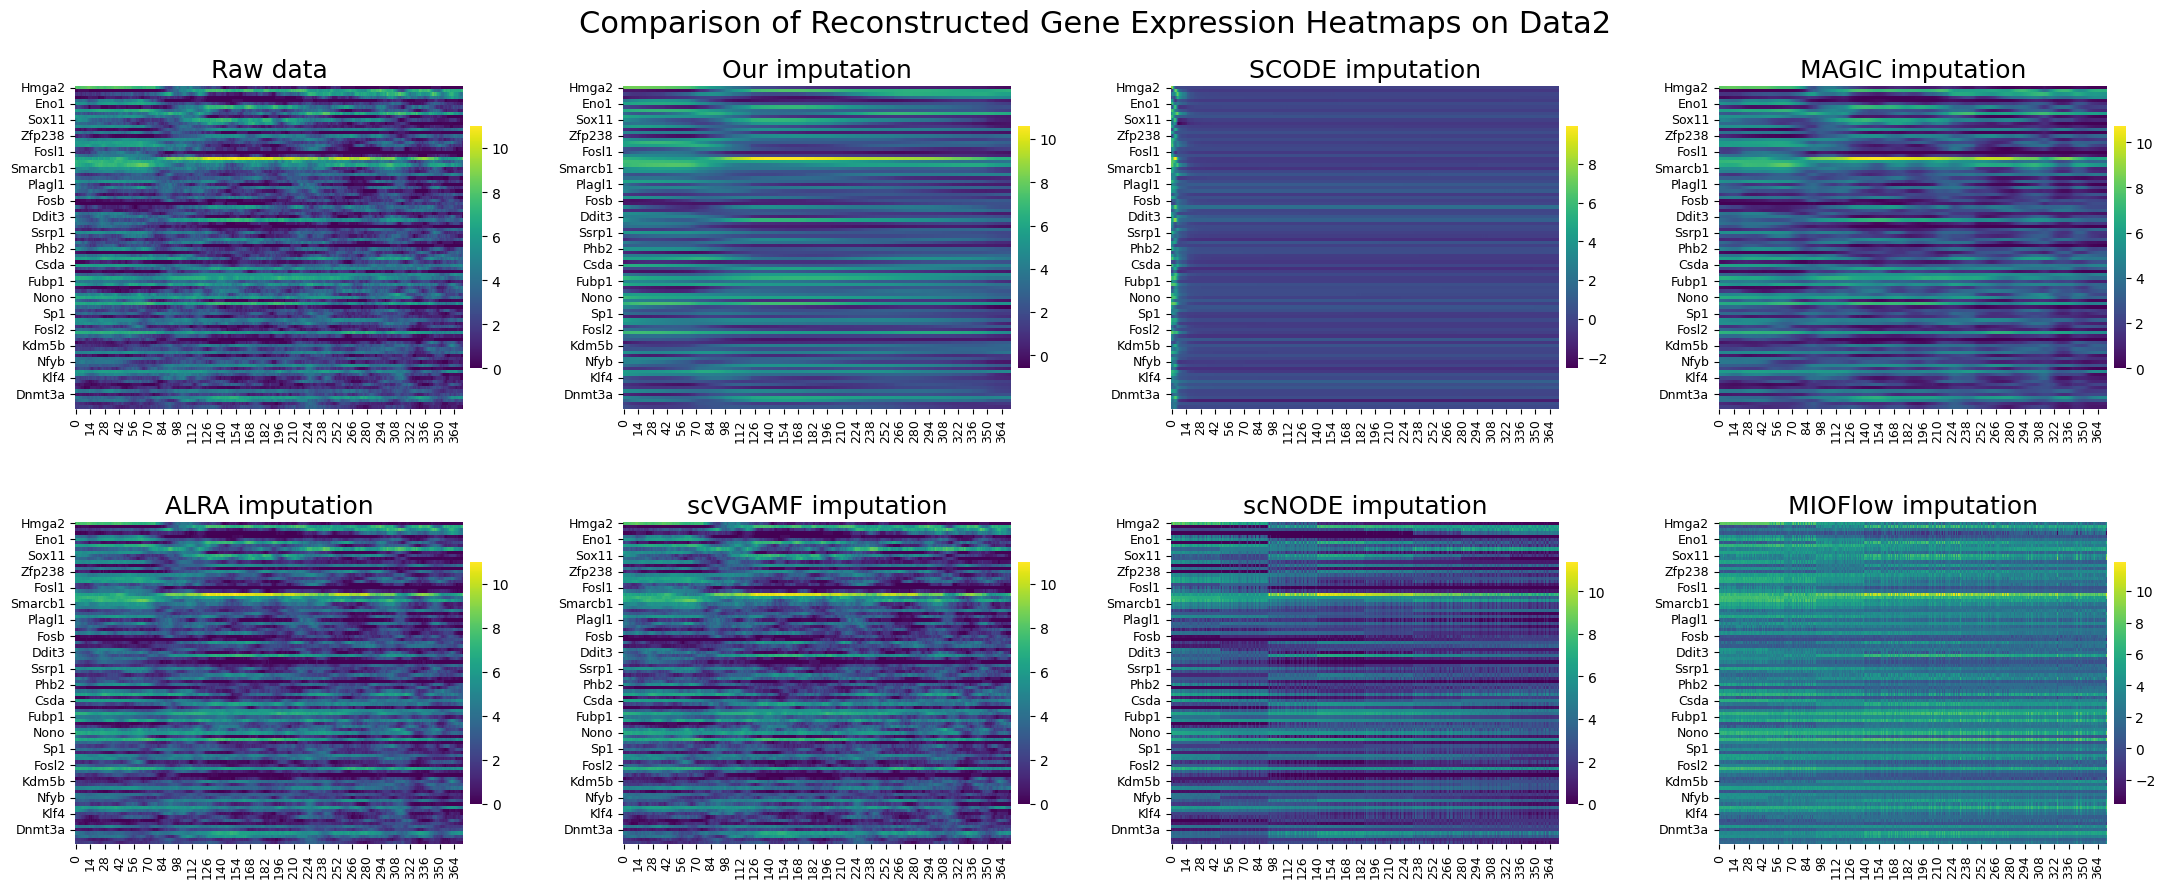

PosixPath('/Users/vinamratasharma/Desktop/ODE_PERTURBATIONS/new/Data2/Mouse_MEF_SCODEData2/Data2_heatmap.svg')

In [20]:

import seaborn as sns

n_panels = len(imputation_results)
n_cols = min(4, max(1, n_panels))
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.8 * n_cols, 4.8 * n_rows))
axes = np.asarray(axes).reshape(-1)

gene_labels = [str(gene) for gene in A_signed_SCODEGS.index]
selected_gene_idx = np.arange(0, len(gene_labels), 5)

for ax, (title, X_cells_by_genes) in zip(axes, imputation_results):
    sns.heatmap(np.asarray(X_cells_by_genes).T, ax=ax, cmap="viridis", cbar_kws={"shrink": 0.75, "pad": 0.015})
    ax.set_title(title, fontsize=18)
    ax.set_yticks(selected_gene_idx + 0.5)
    ax.set_yticklabels([gene_labels[i] for i in selected_gene_idx], fontsize=9, rotation=0)
    ax.tick_params(axis="x", labelsize=9)
    if ax.collections:
        cbar = ax.collections[0].colorbar
        if cbar is not None:
            cbar.ax.tick_params(labelsize=10)
for ax in axes[n_panels:]:
    ax.axis("off")
fig.text(0.5, 0.98, "Comparison of Reconstructed Gene Expression Heatmaps on Data2", ha="center", va="top", fontsize=22)
fig.subplots_adjust(top=0.90, wspace=0.18, hspace=0.35)
heatmap_path = NOTEBOOK_DIR / "Data2_heatmap.svg"
fig.savefig(heatmap_path, bbox_inches="tight")
plt.show()
heatmap_path



# 3. Trajectory


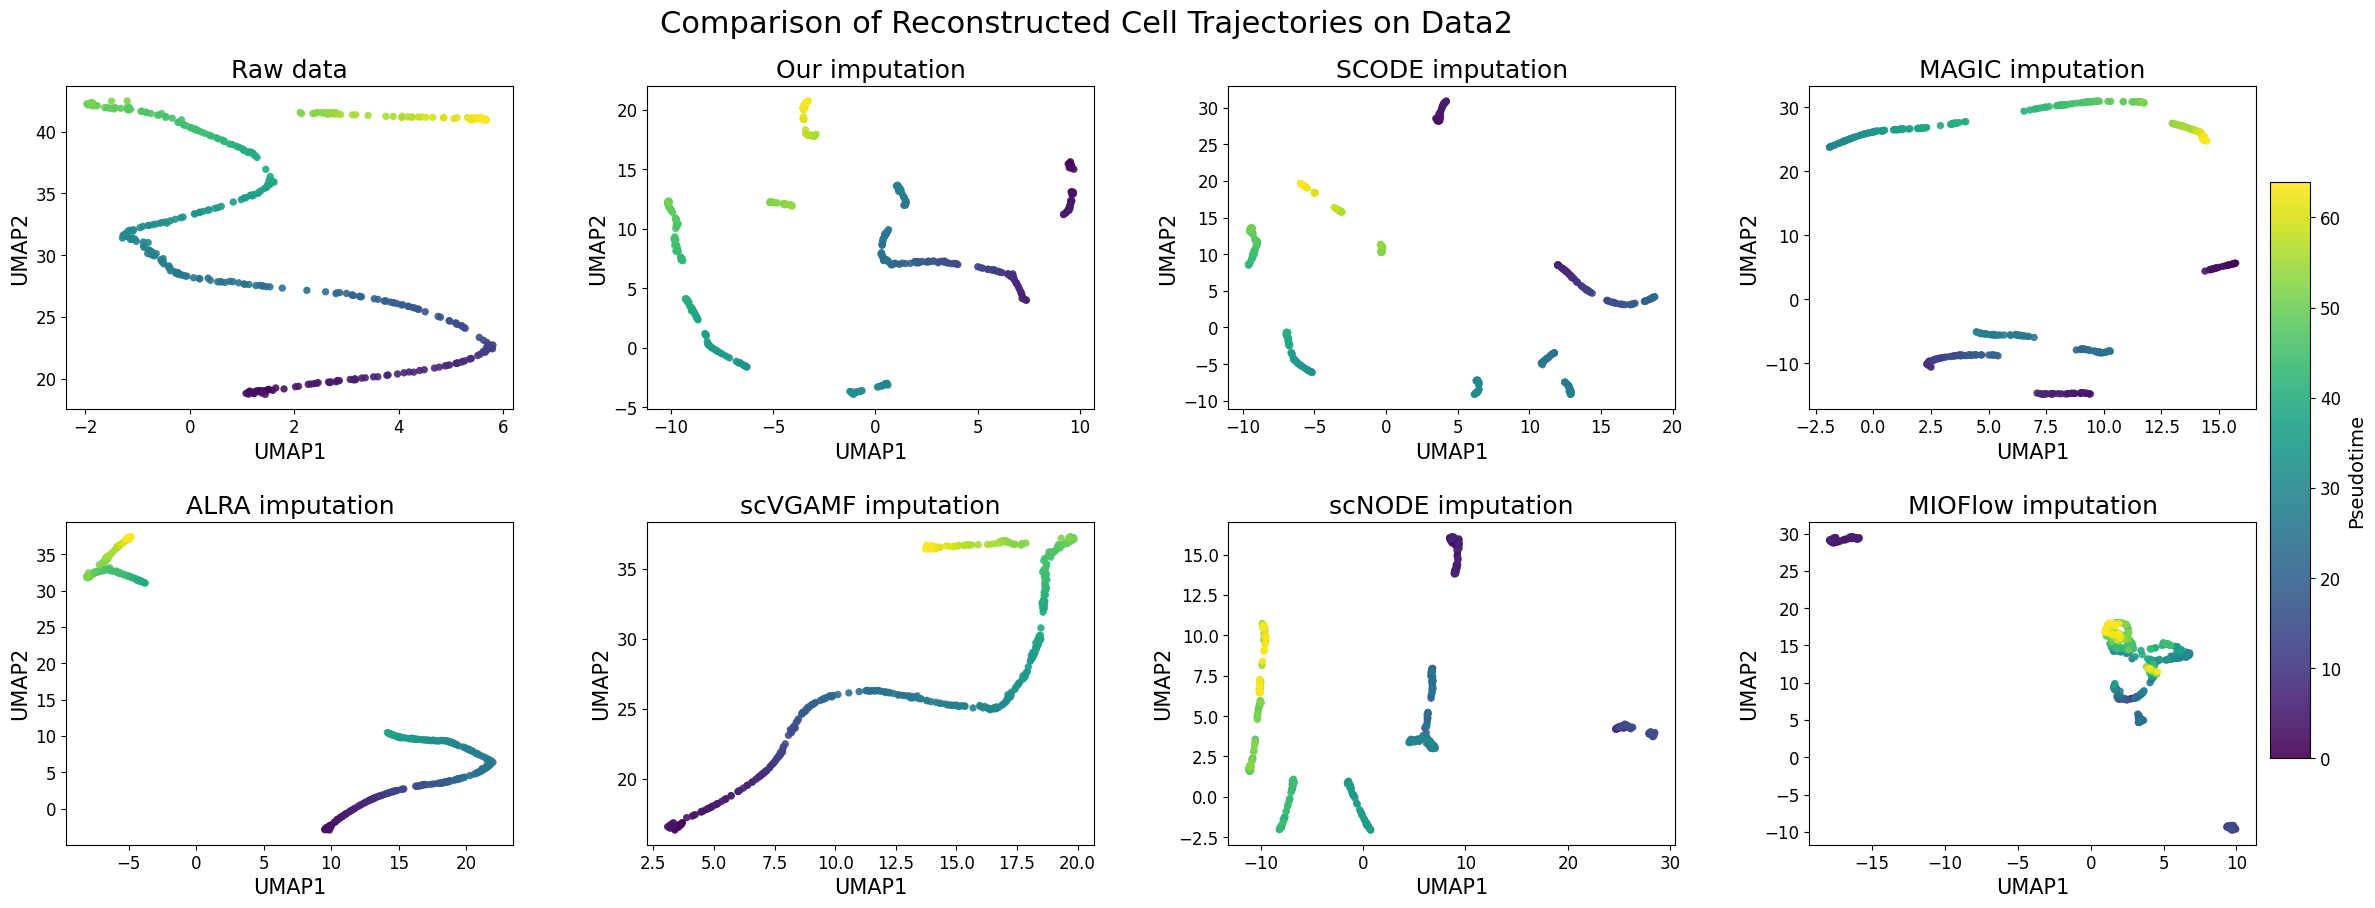

PosixPath('/Users/vinamratasharma/Desktop/ODE_PERTURBATIONS/new/Data2/Mouse_MEF_SCODEData2/Data2_trajectory.svg')

In [21]:

import umap
import matplotlib.pyplot as plt

n_panels = len(imputation_results)
n_cols = min(4, max(1, n_panels))
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.8 * n_cols, 4.8 * n_rows))
axes = np.asarray(axes).reshape(-1)
scatter = None

for ax, (title, X_cells_by_genes) in zip(axes, imputation_results):
    embedding = umap.UMAP(random_state=0).fit_transform(np.asarray(X_cells_by_genes))
    scatter = ax.scatter(embedding[:, 0], embedding[:, 1], c=t_values_np, s=28, alpha=0.9, linewidths=0)
    ax.set_title(title, fontsize=18)
    ax.set_xlabel("UMAP1", fontsize=15)
    ax.set_ylabel("UMAP2", fontsize=15)
    ax.tick_params(axis="both", labelsize=12)
for ax in axes[n_panels:]:
    ax.axis("off")
fig.text(0.5, 0.98, "Comparison of Reconstructed Cell Trajectories on Data2", ha="center", va="top", fontsize=22)
fig.subplots_adjust(top=0.90, right=0.93, wspace=0.30, hspace=0.35)
cbar_ax = fig.add_axes([0.935, 0.2, 0.015, 0.6])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label("Pseudotime", fontsize=14)
cbar.ax.tick_params(labelsize=12)
trajectory_path = NOTEBOOK_DIR / "Data2_trajectory.svg"
fig.savefig(trajectory_path, bbox_inches="tight")
plt.show()
trajectory_path



# 4. Trajectory Ordering Scores


In [22]:

from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from scipy.stats import kendalltau, rankdata


def infer_pseudotime(x):
    x = np.asarray(x, dtype=float)
    latent = PCA(n_components=min(20, x.shape[0] - 1, x.shape[1]), random_state=0).fit_transform(x)
    return latent[:, 0]


def pos_score(pseudotime, true_order):
    true_order = np.asarray(true_order, dtype=float)
    denom = np.triu(np.abs(true_order[:, None] - true_order[None, :])).sum()
    ordered = true_order[np.argsort(np.asarray(pseudotime, dtype=float))]
    numer = np.triu(ordered[None, :] - ordered[:, None]).sum()
    return float(abs(numer / denom)) if denom > 0 else np.nan


def wasserstein_1(x, y):
    n = min(len(x), len(y))
    cost = cdist(np.asarray(x[:n], dtype=float), np.asarray(y[:n], dtype=float), metric="euclidean")
    row_ind, col_ind = linear_sum_assignment(cost)
    return float(cost[row_ind, col_ind].mean())


time_labels = np.asarray(t_values_np, dtype=float).reshape(-1)
true_order = rankdata(time_labels, method="dense").astype(int)
raw_cells = np.asarray(GeneExp_Raw_T, dtype=float)
dist_pca = PCA(n_components=min(20, raw_cells.shape[0] - 1, raw_cells.shape[1]), random_state=0)
raw_latent = dist_pca.fit_transform(raw_cells)
score_rows = []
distribution_rows = []
for method, X_cells_by_genes in imputation_results:
    X_cells_by_genes = np.asarray(X_cells_by_genes, dtype=float)
    pseudotime = infer_pseudotime(X_cells_by_genes)
    tau, _ = kendalltau(pseudotime, true_order)
    score_rows.append({"method": method, "POS": pos_score(pseudotime, true_order), "Kendall": float(abs(tau)) if tau is not None else np.nan})
    X_latent = dist_pca.transform(X_cells_by_genes)
    for t in np.unique(time_labels):
        mask = np.isclose(time_labels, t)
        distribution_rows.append({"method": method, "time": float(t), "W1": wasserstein_1(X_latent[mask], raw_latent[mask])})
order_df = pd.DataFrame(score_rows)
distribution_df = pd.DataFrame(distribution_rows)
trajectory_summary_df = order_df.merge(distribution_df.groupby("method", as_index=False)[["W1"]].mean(), on="method").sort_values(["W1", "POS"], ascending=[True, False])
trajectory_summary_path = NOTEBOOK_DIR / "Data2_trajectory_scores_summary.csv"
trajectory_by_time_path = NOTEBOOK_DIR / "Data2_trajectory_scores_by_time.csv"
trajectory_summary_df.to_csv(trajectory_summary_path, index=False)
distribution_df.to_csv(trajectory_by_time_path, index=False)
display(trajectory_summary_df.round(4))



,method,POS,Kendall,W1
0,Raw data,0.6840,0.4882,0.0000
5,scVGAMF imputation,0.6840,0.4882,0.0125
4,ALRA imputation,0.6765,0.4825,0.3898
3,MAGIC imputation,0.6967,0.5082,2.6486
1,Our imputation,0.7660,0.5853,6.2572
6,scNODE imputation,0.6921,0.5100,7.5337
7,MIOFlow imputation,0.7554,0.5633,11.2650
2,SCODE imputation,1.0000,0.9988,30.3456


# 5. Top-AUROC Gene Trajectories


In [ ]:

from sklearn.metrics import roc_auc_score


def auroc_by_row(A_pre, A_true):
    A_pre = np.asarray(A_pre, dtype=float)
    A_true = np.asarray(A_true, dtype=int)
    out = np.full(A_true.shape[0], np.nan, dtype=float)
    for i in range(A_true.shape[0]):
        if np.unique(A_true[i]).size >= 2:
            out[i] = roc_auc_score(A_true[i], A_pre[i])
    return out


def plot_top_auroc_gene_trajectories(top_n=4, genes_to_plot=None):
    A_ours_used = np.asarray(final_A, dtype=float)
    A_true_np = A_binary_SCODEGS.values.astype(int)
    auroc_ours = auroc_by_row(np.abs(A_ours_used), A_true_np)
    auroc_scode = auroc_by_row(np.abs(A_scode), A_true_np)
    gene_names = [str(g) for g in A_binary_SCODEGS.index]
    if genes_to_plot is None:
        valid_idx = np.flatnonzero(~np.isnan(auroc_ours))
        selected_idx = valid_idx[np.argsort(auroc_ours[valid_idx])[::-1]][:top_n]
    else:
        name_to_idx = {g: i for i, g in enumerate(gene_names)}
        selected_idx = np.array([name_to_idx[g] if isinstance(g, str) else int(g) for g in genes_to_plot], dtype=int)
    obs_np = Y_obs_Smooth.squeeze(0).detach().cpu().numpy()
    ours_np = Y_pred_np
    scode_np = Y_obs_SCODE_np
    fig, axes = plt.subplots(1, len(selected_idx), figsize=(4.4 * len(selected_idx), 3.4), sharex=True)
    axes = np.asarray(axes).reshape(-1)
    for ax, gene_idx in zip(axes, selected_idx):
        ax.plot(t_values_np, obs_np[:, gene_idx], color="black", linewidth=2, label="Observed")
        ax.plot(t_values_np, ours_np[:, gene_idx], color="#4C78A8", linewidth=2, label="Ours")
        ax.plot(t_values_np, scode_np[:, gene_idx], color="#F58518", linewidth=2, label="SCODE")
        ax.set_title(f"{gene_names[gene_idx]}\nOurs AUROC={auroc_ours[gene_idx]:.2f}, SCODE={auroc_scode[gene_idx]:.2f}", fontsize=11)
        ax.set_xlabel("Pseudotime")
        ax.set_ylabel("Expression")
    axes[0].legend(frameon=False, fontsize=9)
    fig.tight_layout()
    out_path = NOTEBOOK_DIR / "Data2_top_auroc_gene_trajectories.svg"
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    selected_df = pd.DataFrame({
        "gene": [gene_names[i] for i in selected_idx],
        "ours_auroc": auroc_ours[selected_idx],
        "scode_auroc": auroc_scode[selected_idx],
    })
    selected_df.to_csv(NOTEBOOK_DIR / "Data2_top_auroc_gene_trajectories.csv", index=False)
    display(selected_df)
    return selected_df

selected_top_auroc_genes_df = plot_top_auroc_gene_trajectories(top_n=4)



# 6. Direction F1 Scores


In [ ]:
# Manually enter the signed-direction F1 scores to plot.
manual_f1_scores = {
    "Ours": 0.0,   # replace with our F1 score
    "SCODE": 0.0,   # replace with SCODE F1 score
}

manual_f1_df = pd.DataFrame(
    [{"method": method, "f1": float(score)} for method, score in manual_f1_scores.items()]
)
manual_f1_path = NOTEBOOK_DIR / "Data2_SCODEGS_manual_direction_f1_scores.csv"
manual_f1_df.to_csv(manual_f1_path, index=False)
display(manual_f1_df)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
colors = {"Ours": "#8FB7D6", "SCODE": "#FDBB7C"}
bars = ax.bar(
    manual_f1_df["method"],
    manual_f1_df["f1"],
    color=[colors.get(method, "#9CA3AF") for method in manual_f1_df["method"]],
    width=0.58,
)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("F1 score")
ax.set_title("Data2 SCODEGS Direction F1 Scores")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
manual_f1_fig_path = NOTEBOOK_DIR / "Data2_SCODEGS_manual_direction_f1_scores.svg"
fig.savefig(manual_f1_fig_path, bbox_inches="tight")
plt.show()
manual_f1_path


## 7. Gene-Centered Signed Network


In [ ]:

import importlib
import sys

for module_dir in (NOTEBOOK_DIR, NOTEBOOK_DIR.parent):
    module_dir_str = str(module_dir)
    if module_dir_str not in sys.path:
        sys.path.insert(0, module_dir_str)

import signed_gene_network_plot
signed_gene_network_plot = importlib.reload(signed_gene_network_plot)
summary_df = signed_gene_network_plot.summarize_signed_gene_candidates(
    gt_df=A_signed_SCODEGS,
    A_ours_path=OURS_A_PATH,
    A_scode_matrix=A_scode,
    top_k_model_edges=None,
    output_root=NOTEBOOK_DIR,
    output_stem="Data2_simplified_signed_gene_network_candidates_SCODEGS",
)
display(summary_df.head(10))
selected_genes = summary_df.loc[summary_df["showcase_eligible"]].head(3)["gene"].tolist()
generated_gene_summaries = []
for gene_name in selected_genes:
    fig, edge_df, score_df = signed_gene_network_plot.plot_signed_gene_network_comparison(
        gene_name=gene_name,
        gt_df=A_signed_SCODEGS,
        gt_label="SCODEGS",
        A_ours_path=OURS_A_PATH,
        A_scode_matrix=A_scode,
        top_k_model_edges=None,
        max_display_tfs=10,
        max_false_positive_tfs=0,
        include_false_positives=False,
        output_root=NOTEBOOK_DIR,
        output_stem=f"Data2_simplified_signed_gene_network_{gene_name}_SCODEGS",
    )
    display(fig)
    plt.close(fig)
    ours_score = score_df.loc[score_df["method"] == "Ours"].iloc[0]
    scode_score = score_df.loc[score_df["method"] == "SCODE"].iloc[0]
    generated_gene_summaries.append({
        "gene": gene_name,
        "gt_edge_count": int(ours_score["gt_edge_count"]),
        "ours_correct_sign_count": int(ours_score["correct_sign_count"]),
        "scode_correct_sign_count": int(scode_score["correct_sign_count"]),
        "ours_signed_recovery": float(ours_score["signed_recovery"]),
        "scode_signed_recovery": float(scode_score["signed_recovery"]),
        "delta_signed_recovery": float(ours_score["signed_recovery"] - scode_score["signed_recovery"]),
    })
generated_gene_summaries_df = pd.DataFrame(generated_gene_summaries)
generated_gene_summaries_df.to_csv(NOTEBOOK_DIR / "Data2_simplified_signed_gene_network_summary_SCODEGS.csv", index=False)
display(generated_gene_summaries_df)



## 8. TF-Centered Signed Network and F1 Ranks


In [ ]:

import importlib
import sys

def signed_call_from_weights(values, top_k=None, abs_threshold=None):
    values = np.asarray(values, dtype=float)
    signed = np.zeros(values.shape, dtype=int)
    idx = np.flatnonzero(np.isfinite(values) & (np.abs(values) > 0))
    if abs_threshold is not None:
        idx = idx[np.abs(values[idx]) >= abs_threshold]
    if top_k is not None and idx.size > top_k:
        strongest = np.argsort(np.abs(values[idx]))[-top_k:]
        idx = idx[np.sort(strongest)]
    signed[idx] = np.sign(values[idx]).astype(int)
    return signed


def signed_f1_stats(gt_signed, pred_signed):
    gt_signed = np.asarray(gt_signed, dtype=int)
    pred_signed = np.asarray(pred_signed, dtype=int)
    correct = (gt_signed != 0) & (pred_signed == gt_signed)
    tp = int(correct.sum())
    fp = int(((pred_signed != 0) & ~correct).sum())
    fn = int(((gt_signed != 0) & ~correct).sum())
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1}


method_matrices = {"Ours": final_A, "SCODE": A_scode}

for module_dir in (NOTEBOOK_DIR, NOTEBOOK_DIR.parent):
    module_dir_str = str(module_dir)
    if module_dir_str not in sys.path:
        sys.path.insert(0, module_dir_str)

import signed_tf_network_plot
signed_tf_network_plot = importlib.reload(signed_tf_network_plot)
summary_tf_df = signed_tf_network_plot.summarize_signed_tf_visual_candidates(
    gt_df=A_signed_SCODEGS,
    A_ours_path=OURS_A_PATH,
    A_scode_matrix=A_scode,
    top_k_model_edges=None,
    output_root=NOTEBOOK_DIR,
    output_stem="Data2_simplified_signed_tf_network_candidates_SCODEGS",
)
display(summary_tf_df.head(10))
selected_tfs = summary_tf_df.loc[summary_tf_df["visual_showcase_eligible"]].head(3)["tf"].tolist()
generated_tf_summaries = []
for tf_name in selected_tfs:
    fig, edge_df, score_df = signed_tf_network_plot.plot_signed_tf_network_comparison(
        tf_name=tf_name,
        gt_df=A_signed_SCODEGS,
        gt_label="SCODEGS",
        A_ours_path=OURS_A_PATH,
        A_scode_matrix=A_scode,
        top_k_model_edges=None,
        max_display_genes=10,
        max_false_positive_genes=0,
        include_false_positives=False,
        output_root=NOTEBOOK_DIR,
        output_stem=f"Data2_simplified_signed_tf_network_{tf_name}_SCODEGS",
    )
    display(fig)
    plt.close(fig)
    ours_score = score_df.loc[score_df["method"] == "Ours"].iloc[0]
    scode_score = score_df.loc[score_df["method"] == "SCODE"].iloc[0]
    generated_tf_summaries.append({
        "tf": tf_name,
        "gt_edge_count": int(ours_score["gt_edge_count"]),
        "ours_correct_sign_count": int(ours_score["correct_sign_count"]),
        "scode_correct_sign_count": int(scode_score["correct_sign_count"]),
        "ours_signed_recovery": float(ours_score["signed_recovery"]),
        "scode_signed_recovery": float(scode_score["signed_recovery"]),
        "delta_signed_recovery": float(ours_score["signed_recovery"] - scode_score["signed_recovery"]),
    })
generated_tf_summaries_df = pd.DataFrame(generated_tf_summaries)
generated_tf_summaries_df.to_csv(NOTEBOOK_DIR / "Data2_simplified_signed_tf_network_summary_SCODEGS.csv", index=False)
display(generated_tf_summaries_df)

# Per-TF signed F1/precision/recall table.
tf_rows = []
for tf_idx, tf_name in enumerate(A_signed_SCODEGS.columns.astype(str)):
    gt_signed = A_signed_SCODEGS.iloc[:, tf_idx].to_numpy(dtype=int)
    gt_edge_count = int((gt_signed != 0).sum())
    for method, matrix in method_matrices.items():
        pred_signed = signed_call_from_weights(np.asarray(matrix)[:, tf_idx])
        stats = signed_f1_stats(gt_signed, pred_signed)
        tf_rows.append({"tf": tf_name, "method": method, "gt_edge_count": gt_edge_count, **stats})
tf_signed_f1_df = pd.DataFrame(tf_rows)
tf_signed_f1_df["rank_key"] = tf_signed_f1_df["f1"]
tf_signed_f1_path = NOTEBOOK_DIR / "Data2_SCODEGS_tf_signed_f1_precision_recall.csv"
tf_signed_f1_df.to_csv(tf_signed_f1_path, index=False)
display(tf_signed_f1_df.sort_values(["method", "f1", "recall"], ascending=[True, False, False]).head(20))
tf_signed_f1_path

